In [1]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))
# Now import Model from freeflux

import numpy as np

import seaborn as sns
import analysis.io_func as io_func
import analysis.an_func as an_func
import matplotlib.pyplot as plt
from analysis import config_13c as config
import umap

/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:104: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.substrates_info = pd.concat((self.substrates_info, newSubs))
/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:132: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.products_info = pd.concat((self.products_info, newPros))
/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:

calc pairwise distance for TM6 and WT net flux configuartions
to show that WT configurations are similar with each other

In [2]:
import thermo_flux

In [3]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [8]:
condition = cond = 'TM6'
model=config.model
df_tm6=config.full_flux_df(condition)



In [9]:
condition = cond = 'WT'
model=config.model
df_wt=config.full_flux_df(condition)



WT: median = 4.28, IQR = 3.75-4.94, n pairs = 499500
TM6: median = 16.94, IQR = 13.36-23.27, n pairs = 499500


/tmp/ipykernel_78602/3584710890.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dist_df, x='strain', y='distance', ax=axs[1],


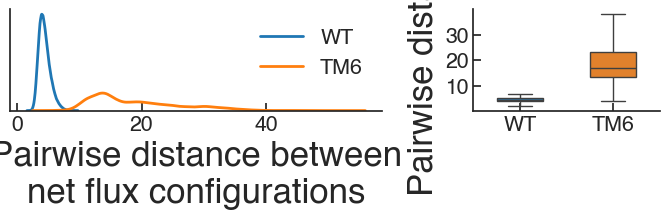

In [ ]:
from scipy.spatial.distance import pdist

def pairwise_distances_two_strains(df_wt, df_tm6, glc_id='GLCt+0',
                                   scaling='pooled_std', max_samples=2000, seed=0):
    """
    df_wt, df_tm6: DataFrames with reactions as index and samples as columns.
    Returns a dict with the pairwise distances of each strain.
    """
    rng = np.random.default_rng(seed)

    # keep reactions present in both strains
    common = df_wt.index.intersection(df_tm6.index)
    wt, tm6 = df_wt.loc[common], df_tm6.loc[common]

    # normalize each configuration to its glucose uptake
    wt = wt / wt.loc[glc_id].abs()
    tm6 = tm6 / tm6.loc[glc_id].abs()
    wt, tm6 = wt.drop(index=glc_id), tm6.drop(index=glc_id)

    # pooled scaling: same scale per reaction for both strains
    pooled = pd.concat([wt, tm6], axis=1)
    if scaling == 'pooled_std':
        scale = pooled.std(axis=1)
    elif scaling == 'pooled_range':
        scale = pooled.max(axis=1) - pooled.min(axis=1)
    else:
        scale = pd.Series(1.0, index=pooled.index)
    keep = scale > 1e-12                      # drop reactions that never vary
    wt = wt.loc[keep].div(scale[keep], axis=0)
    tm6 = tm6.loc[keep].div(scale[keep], axis=0)

    dists = {}
    for name, df in [('WT', wt), ('TM6', tm6)]:
        X = df.T.values                       # samples x reactions
        if X.shape[0] > max_samples:          # subsample to limit memory
            X = X[rng.choice(X.shape[0], max_samples, replace=False)]
        dists[name] = pdist(X, metric='euclidean')
    return dists

dists = pairwise_distances_two_strains(df_wt, df_tm6)

for name, d in dists.items():
    print(f'{name}: median = {np.median(d):.2f}, IQR = '
          f'{np.percentile(d, 25):.2f}-{np.percentile(d, 75):.2f}, n pairs = {len(d)}')


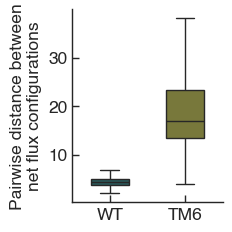

In [ ]:
## plot
fig, ax = plt.subplots(figsize=(2.5, 2.5))
io_func.scale_rcparams(fig, scalingf=0.5)
colors = {'WT': palette[0], 'TM6': palette[2]}

dist_df = pd.concat([pd.DataFrame({'distance': d, 'strain': n}) for n, d in dists.items()])
sns.boxplot(data=dist_df, x='strain', y='distance', ax=ax,
            hue='strain', palette=colors, legend=False,
            showfliers=False, width=0.5)
ax.set_xlabel('')
ax.set_ylabel('Pairwise distance between\nnet flux configurations')

plt.tight_layout()
# plt.savefig(f'{config.PLOTS_FOLDER}/pairwise_distances_boxplot_2strains.svg', bbox_inches='tight')